In [2]:
# libraries
import os

os.environ["PROJ_LIB"] = "/home/arcturus/miniconda3/share/proj"
from mpl_toolkits.basemap import Basemap
import matplotlib.pyplot as plt
import numpy as np

from config import Continent

%load_ext autoreload
%autoreload 2

In [14]:
TEXT_OFFSET = 10

/home/arcturus/miniconda3/lib/python3.7/site-packages/ipykernel_launcher.py:16: MatplotlibDeprecationWarning: 
The dedent function was deprecated in Matplotlib 3.1 and will be removed in 3.3. Use inspect.cleandoc instead.
  app.launch_new_instance()
/home/arcturus/miniconda3/lib/python3.7/site-packages/ipykernel_launcher.py:25: MatplotlibDeprecationWarning: 
The dedent function was deprecated in Matplotlib 3.1 and will be removed in 3.3. Use inspect.cleandoc instead.


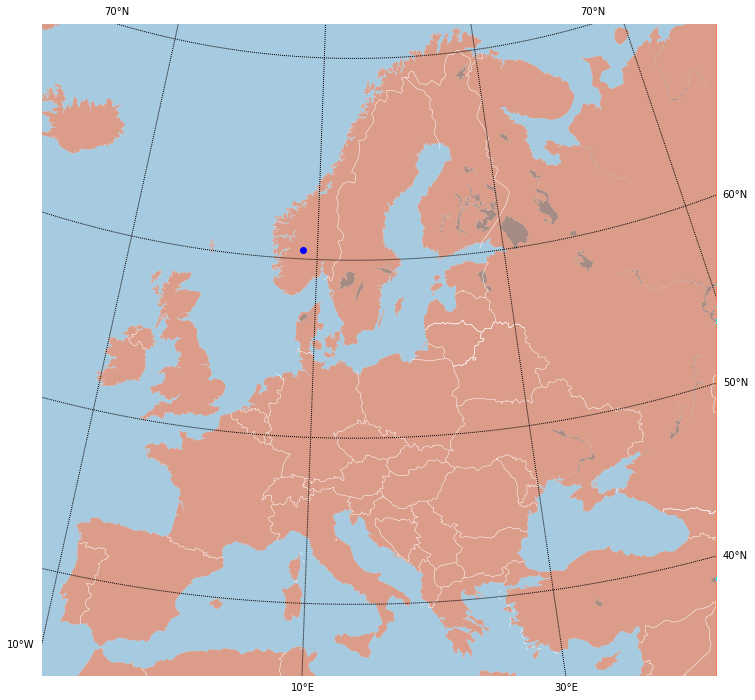

In [42]:
plt.figure(figsize=(20, 12))

# Control the position of the square. Give the coordinate of 2 corners
m = Basemap(
            # width=Continent.europe['width'],
            # height=Continent.europe['height'],
            # lat_0=Continent.europe['lat_0'],
            lon_0=Continent.europe['lon_0'],
            lat_1=Continent.europe['lat_1'],
            lat_2=Continent.europe['lat_2'],
            llcrnrlon=Continent.europe['llcrnrlon'],
            llcrnrlat=Continent.europe['llcrnrlat'],
            urcrnrlon=Continent.europe['urcrnrlon'],
            urcrnrlat=Continent.europe['urcrnrlat'],
            projection='lcc',
            resolution='l',  ## c, l, i, h, f
           )

# # Draw the components of the map
m.drawmapboundary(fill_color='#A6CAE0', linewidth=0)
m.fillcontinents(color='coral', alpha=0.6, lake_color='grey')
m.drawcoastlines(linewidth=0.1, color="white")
m.drawlsmask(land_color='coral',ocean_color='aqua',lakes=True)

m.drawcountries(color="white")

# ## Parallels and meridians
parallels = np.arange(0.,81,10.)
meridians = np.arange(10.,351.,20.)
m.drawparallels(parallels, labels=[False,True,True,False])
m.drawmeridians(meridians, labels=[True,False,False,True])

# lon, lat = 8.468946, 60.472024
x, y = m(lon, lat)   ## Map projection
x_off, y_off = x + TEXT_OFFSET, y + TEXT_OFFSET
lon, lat = m(x, y, inverse=True)  ## Back to longitude-latitude
m.plot(x, y, 'bo')

# plt.text
(x_off, y_off, "Norway ({:.1f}, {:.1f})".format(lon, lat))
plt.show()

In [51]:
m.drawcountries?